In [2]:
#Part A
import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# Directory containing s1, s2, ..., s40
dataset_dir = "."  
IMG_HEIGHT = 112
IMG_WIDTH = 92
NUM_PIXELS = IMG_HEIGHT * IMG_WIDTH

images_list = []
labels_list = []

# Load all 400 images (40 subjects x 10 images each)
for subject_id in range(1, 41):
    subject_folder = os.path.join(dataset_dir, f"s{subject_id}")
    if not os.path.exists(subject_folder):
        continue
    for img_id in range(1, 11):
        img_path = os.path.join(subject_folder, f"{img_id}.pgm")
        # Open grayscale image
        img = Image.open(img_path).convert('L')
        img_arr = np.array(img, dtype=np.float64)
        
        # Flatten (112 x 92) into 1D vector (10304,)
        images_list.append(img_arr.flatten())
        labels_list.append(subject_id)

# Convert to NumPy arrays
X_all = np.array(images_list)   # Shape: (400, 10304)
y_all = np.array(labels_list)   # Shape: (400,)

print("=== Part A: Dataset Inspection ===")
print(f"Total images loaded: {X_all.shape[0]}")
print(f"Original image shape: {IMG_HEIGHT} x {IMG_WIDTH}")
print(f"Flattened feature vector length: {X_all.shape[1]}")
print(f"Pixel intensity range: Min = {X_all.min()}, Max = {X_all.max()}")
print(f"Labels shape: {y_all.shape}, Unique subjects: {len(np.unique(y_all))}")

=== Part A: Dataset Inspection ===
Total images loaded: 400
Original image shape: 112 x 92
Flattened feature vector length: 10304
Pixel intensity range: Min = 0.0, Max = 251.0
Labels shape: (400,), Unique subjects: 40


In [4]:

# PART A 

# Set seed for reproducibility
np.random.seed(42)

train_indices = []
test_indices = []

# For each subject (1 to 40), pick 7 random images for train and 3 for test
for subject_id in range(1, 41):
    subject_idx = np.where(y_all == subject_id)[0]
    shuffled_idx = np.random.permutation(subject_idx)
    
    train_indices.extend(shuffled_idx[:7])  # 7 images for training
    test_indices.extend(shuffled_idx[7:])   # 3 images for testing

train_indices = np.array(train_indices)
test_indices = np.array(test_indices)

# Create the training and testing matrices
X_train, y_train = X_all[train_indices], y_all[train_indices]
X_test, y_test = X_all[test_indices], y_all[test_indices]

print("=== Train-Test Split ===")
print(f"Training set: {X_train.shape[0]} images ({X_train.shape[0]//40} per subject)")
print(f"Test set:     {X_test.shape[0]} images ({X_test.shape[0]//40} per subject)")
print(f"Matrix shape: X_train = {X_train.shape}, X_test = {X_test.shape}")

=== Train-Test Split ===
Training set: 280 images (7 per subject)
Test set:     120 images (3 per subject)
Matrix shape: X_train = (280, 10304), X_test = (120, 10304)


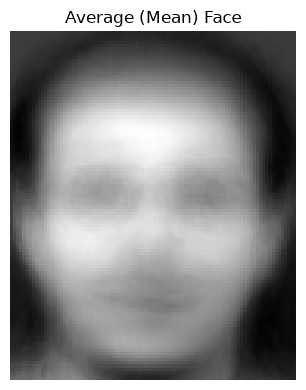

In [6]:

# PART B
# 1. Compute mean face
mean_face = np.mean(X_train, axis=0)  # Shape: (10304,)

# 2. Mean centering (subtract mean face)
Phi_train = X_train - mean_face       # Shape: (280, 10304)
Phi_test = X_test - mean_face         # Shape: (120, 10304)

# 3. Visualize Mean Face
plt.figure(figsize=(4, 4))
plt.imshow(mean_face.reshape(IMG_HEIGHT, IMG_WIDTH), cmap='gray')
plt.title("Average (Mean) Face")
plt.axis('off')
plt.tight_layout()
plt.savefig("mean_face.png", dpi=150)
plt.show()

In [7]:
N = Phi_train.shape[0]  # 280

# ==========================================
# Approach 1: Eigendecomposition of (Phi * Phi^T)
# ==========================================
# Surrogate covariance matrix L of size (N, N) = (280, 280)
L = (Phi_train @ Phi_train.T) / N

# Compute eigenvalues and eigenvectors of L
eigenvalues_L, eigenvectors_L = np.linalg.eigh(L)

# Sort in descending order
idx_sorted = np.argsort(eigenvalues_L)[::-1]
eigenvalues = eigenvalues_L[idx_sorted]
eigenvectors_L = eigenvectors_L[:, idx_sorted]

# Map back to high-dimensional space: u_i = Phi^T * v_i
eigenfaces_cov = Phi_train.T @ eigenvectors_L  # Shape: (10304, 280)

# Normalize each eigenface to unit length
eigenfaces_cov = eigenfaces_cov / np.linalg.norm(eigenfaces_cov, axis=0, keepdims=True)

# ==========================================
# Approach 2: Singular Value Decomposition (SVD)
# ==========================================
# Phi_train = U * S * Vt
U_svd, S_svd, Vt_svd = np.linalg.svd(Phi_train, full_matrices=False)
eigenfaces_svd = Vt_svd.T  # Shape: (10304, 280)
eigenvalues_svd = (S_svd ** 2) / N

# ==========================================
# Compare the Two Approaches
# ==========================================
print("=== Comparing Covariance Eigendecomposition vs SVD ===")
print("Top 5 Eigenvalues (Covariance):", np.round(eigenvalues[:5], 2))
print("Top 5 Eigenvalues (from SVD):  ", np.round(eigenvalues_svd[:5], 2))
print("Max absolute difference in eigenvalues:", np.max(np.abs(eigenvalues[:N] - eigenvalues_svd)))

# Check alignment of principal directions (dot product between corresponding vectors should be ~ +1 or -1)
dot_products = np.abs(np.sum(eigenfaces_cov[:, :5] * eigenfaces_svd[:, :5], axis=0))
print("Absolute dot products of top 5 eigenvectors (should all be 1.0):", np.round(dot_products, 4))

=== Comparing Covariance Eigendecomposition vs SVD ===
Top 5 Eigenvalues (Covariance): [2896032.59 2084956.71 1109667.83  868817.47  812981.69]
Top 5 Eigenvalues (from SVD):   [2896032.59 2084956.71 1109667.83  868817.47  812981.69]
Max absolute difference in eigenvalues: 2.7939677238464355e-09
Absolute dot products of top 5 eigenvectors (should all be 1.0): [1. 1. 1. 1. 1.]


=== Explained Variance Analysis ===
Number of components needed for >= 90% variance: k = 91
Exact cumulative variance captured: 90.00%


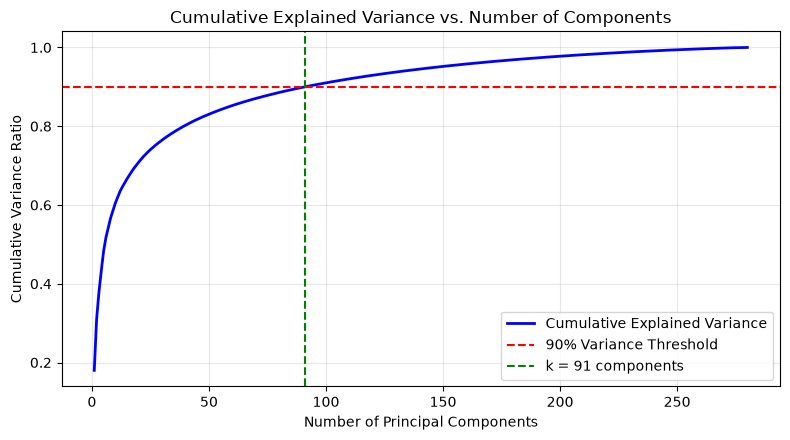

In [8]:
# Compute explained variance ratio
var_ratio = eigenvalues / np.sum(eigenvalues)
cum_var_ratio = np.cumsum(var_ratio)

# Find minimum k to preserve >= 90% variance
k_90 = np.argmax(cum_var_ratio >= 0.90) + 1

print(f"=== Explained Variance Analysis ===")
print(f"Number of components needed for >= 90% variance: k = {k_90}")
print(f"Exact cumulative variance captured: {cum_var_ratio[k_90-1]*100:.2f}%")

# Plot Cumulative Explained Variance
plt.figure(figsize=(8, 4.5))
plt.plot(range(1, len(cum_var_ratio) + 1), cum_var_ratio, 'b-', lw=2, label="Cumulative Explained Variance")
plt.axhline(y=0.90, color='r', linestyle='--', label="90% Variance Threshold")
plt.axvline(x=k_90, color='g', linestyle='--', label=f"k = {k_90} components")
plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Variance Ratio")
plt.title("Cumulative Explained Variance vs. Number of Components")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("explained_variance.png", dpi=150)
plt.show()

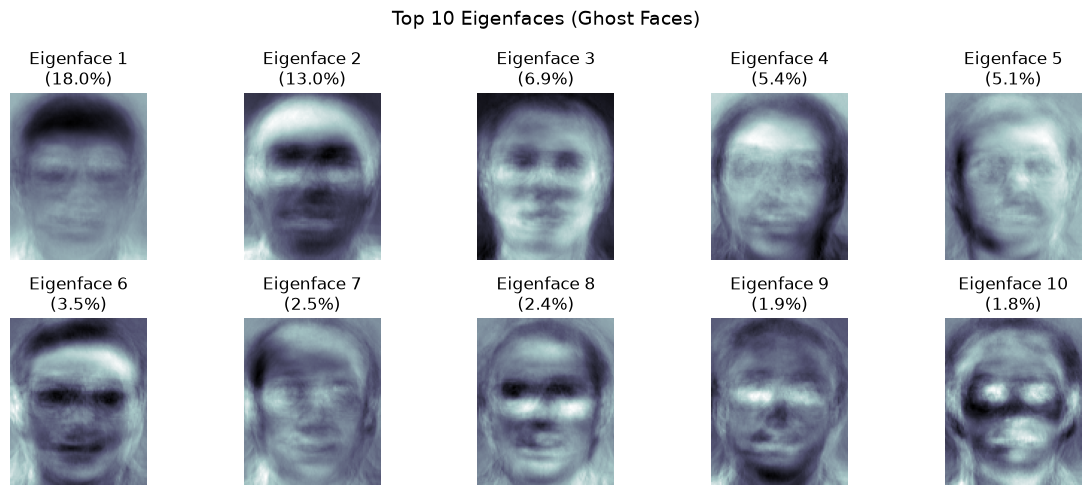

In [9]:
# Pick the top eigenfaces
V_k = eigenfaces_cov[:, :k_90]  # Shape: (10304, k_90)

# Plot the top 10 Eigenfaces
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for i, ax in enumerate(axes.flat):
    eigenface_img = V_k[:, i].reshape(IMG_HEIGHT, IMG_WIDTH)
    ax.imshow(eigenface_img, cmap='bone')
    ax.set_title(f"Eigenface {i+1}\n({var_ratio[i]*100:.1f}%)")
    ax.axis('off')

plt.suptitle("Top 10 Eigenfaces (Ghost Faces)", fontsize=14)
plt.tight_layout()
plt.savefig("eigenfaces.png", dpi=150)
plt.show()

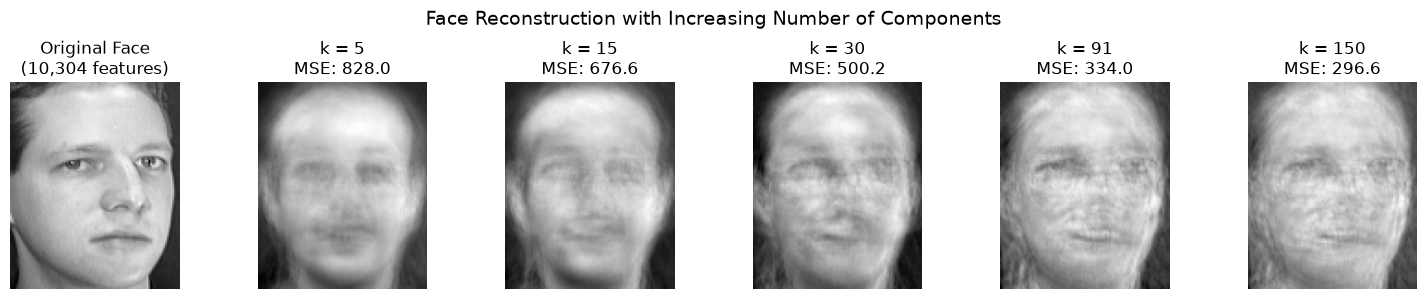

=== Storage & Compression Analysis ===
Original representation: 10304 features (~40.25 KB / face)
PCA representation (k=91): 91 features (~0.36 KB / face)
Compression factor: 113.2x reduction (99.12% space saved!)


In [10]:
# Project training and test sets into reduced k-dimensional space
W_train = Phi_train @ V_k  # Shape: (280, k_90)
W_test = Phi_test @ V_k    # Shape: (120, k_90)

# Select a sample test image to reconstruct
sample_idx = 0
orig_face = X_test[sample_idx]
centered_sample = Phi_test[sample_idx]

k_experiments = [5, 15, 30, k_90, 150]
fig, axes = plt.subplots(1, len(k_experiments) + 1, figsize=(15, 3))

# Original face
axes[0].imshow(orig_face.reshape(IMG_HEIGHT, IMG_WIDTH), cmap='gray')
axes[0].set_title("Original Face\n(10,304 features)")
axes[0].axis('off')

for idx, k_val in enumerate(k_experiments):
    # Truncate eigenfaces to k_val
    V_sub = eigenfaces_cov[:, :k_val]
    # Projection & Reconstruction
    weight = centered_sample @ V_sub
    reconstructed = mean_face + (weight @ V_sub.T)
    
    # Calculate Mean Squared Error (MSE)
    mse = np.mean((orig_face - reconstructed) ** 2)
    
    axes[idx + 1].imshow(reconstructed.reshape(IMG_HEIGHT, IMG_WIDTH), cmap='gray')
    axes[idx + 1].set_title(f"k = {k_val}\nMSE: {mse:.1f}")
    axes[idx + 1].axis('off')

plt.suptitle("Face Reconstruction with Increasing Number of Components", fontsize=14)
plt.tight_layout()
plt.savefig("reconstruction_comparison.png", dpi=150)
plt.show()

# Storage Comparison
orig_storage_per_face = NUM_PIXELS * 4 / 1024       # in KB (assuming 32-bit float)
pca_storage_per_face = k_90 * 4 / 1024              # in KB
compression_ratio = NUM_PIXELS / k_90

print("=== Storage & Compression Analysis ===")
print(f"Original representation: {NUM_PIXELS} features (~{orig_storage_per_face:.2f} KB / face)")
print(f"PCA representation (k={k_90}): {k_90} features (~{pca_storage_per_face:.2f} KB / face)")
print(f"Compression factor: {compression_ratio:.1f}x reduction ({100*(1 - k_90/NUM_PIXELS):.2f}% space saved!)")

In [11]:
#PART-C

import time

# Function to perform Nearest Neighbor matching using Euclidean distance
def nearest_neighbor_classify(train_features, train_labels, test_features):
    # Vectorized pairwise Euclidean distance: ||a - b||
    # Using broadcasting: (N_test, 1, D) - (1, N_train, D)
    dists = np.linalg.norm(test_features[:, np.newaxis, :] - train_features[np.newaxis, :, :], axis=2)
    best_match_indices = np.argmin(dists, axis=1)
    predictions = train_labels[best_match_indices]
    return predictions, best_match_indices, dists

# 1. Matching in PCA Space
t0 = time.time()
pred_pca, match_idx_pca, dists_pca = nearest_neighbor_classify(W_train, y_train, W_test)
pca_time = time.time() - t0
acc_pca = np.mean(pred_pca == y_test) * 100

# 2. Matching in Raw Pixel Space
t0 = time.time()
pred_raw, match_idx_raw, dists_raw = nearest_neighbor_classify(X_train, y_train, X_test)
raw_time = time.time() - t0
acc_raw = np.mean(pred_raw == y_test) * 100

print("=== Part C: Recognition Results ===")
print(f"Recognition Accuracy (PCA space, k={k_90}): {acc_pca:.2f}% (Time: {pca_time*1000:.2f} ms)")
print(f"Recognition Accuracy (Raw Pixel space):     {acc_raw:.2f}% (Time: {raw_time*1000:.2f} ms)")
print(f"Speedup with PCA: {raw_time / pca_time:.1f}x faster distance calculation!")

=== Part C: Recognition Results ===
Recognition Accuracy (PCA space, k=91): 95.83% (Time: 23.86 ms)
Recognition Accuracy (Raw Pixel space):     95.00% (Time: 7518.42 ms)
Speedup with PCA: 315.1x faster distance calculation!


Total test faces: 120
Correct predictions: 115, Incorrect predictions: 5


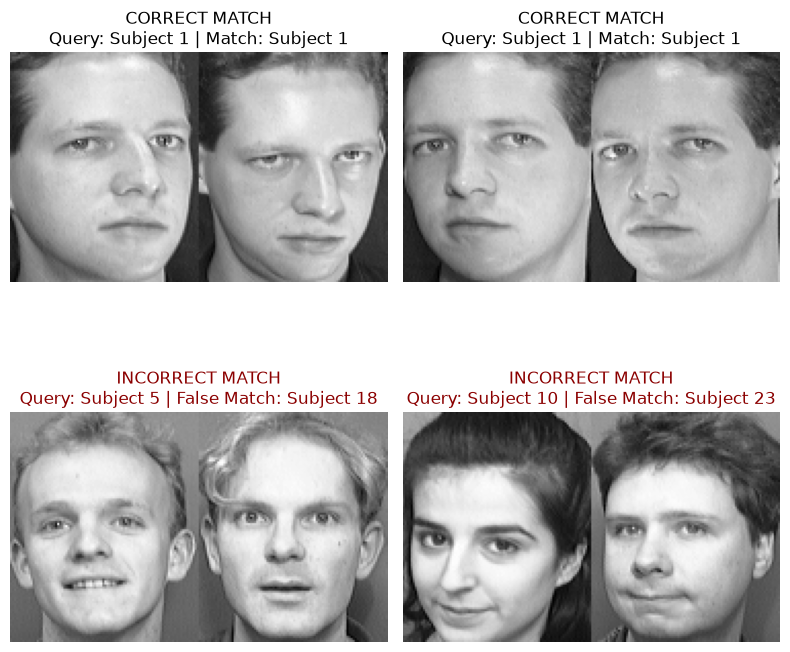

In [12]:
correct_indices = np.where(pred_pca == y_test)[0]
incorrect_indices = np.where(pred_pca != y_test)[0]

print(f"Total test faces: {len(y_test)}")
print(f"Correct predictions: {len(correct_indices)}, Incorrect predictions: {len(incorrect_indices)}")

# Visualize up to 2 Correct Matches and up to 2 Incorrect Matches
num_to_show = min(2, len(incorrect_indices)) if len(incorrect_indices) > 0 else 1
fig, axes = plt.subplots(2, 2, figsize=(8, 8))

# Row 1: Correct Matches
for col in range(2):
    test_i = correct_indices[col]
    matched_train_i = match_idx_pca[test_i]
    
    # Combined side by side: Test on left, Matched Train on right
    pair = np.hstack([X_test[test_i].reshape(IMG_HEIGHT, IMG_WIDTH), 
                      X_train[matched_train_i].reshape(IMG_HEIGHT, IMG_WIDTH)])
    axes[0, col].imshow(pair, cmap='gray')
    axes[0, col].set_title(f"CORRECT MATCH\nQuery: Subject {y_test[test_i]} | Match: Subject {pred_pca[test_i]}")
    axes[0, col].axis('off')

# Row 2: Incorrect Matches (if any)
if len(incorrect_indices) > 0:
    for col in range(min(2, len(incorrect_indices))):
        test_i = incorrect_indices[col]
        matched_train_i = match_idx_pca[test_i]
        
        pair = np.hstack([X_test[test_i].reshape(IMG_HEIGHT, IMG_WIDTH), 
                          X_train[matched_train_i].reshape(IMG_HEIGHT, IMG_WIDTH)])
        axes[1, col].imshow(pair, cmap='gray')
        axes[1, col].set_title(f"INCORRECT MATCH\nQuery: Subject {y_test[test_i]} | False Match: Subject {pred_pca[test_i]}", color='darkred')
        axes[1, col].axis('off')
else:
    axes[1, 0].text(0.5, 0.5, "No Incorrect Matches (100% accuracy!)", ha='center', va='center')
    axes[1, 0].axis('off')
    axes[1, 1].axis('off')

plt.tight_layout()
plt.savefig("match_inspections.png", dpi=150)
plt.show()

=== Part D: Traditional ML Comparison ===
                     Classifier  Accuracy (%)
      Baseline (Euclidean 1-NN)     95.833333
      K-Nearest Neighbors (k=3)     89.166667
Support Vector Machine (Linear)     96.666667
   Support Vector Machine (RBF)     96.666667
            Logistic Regression     98.333333


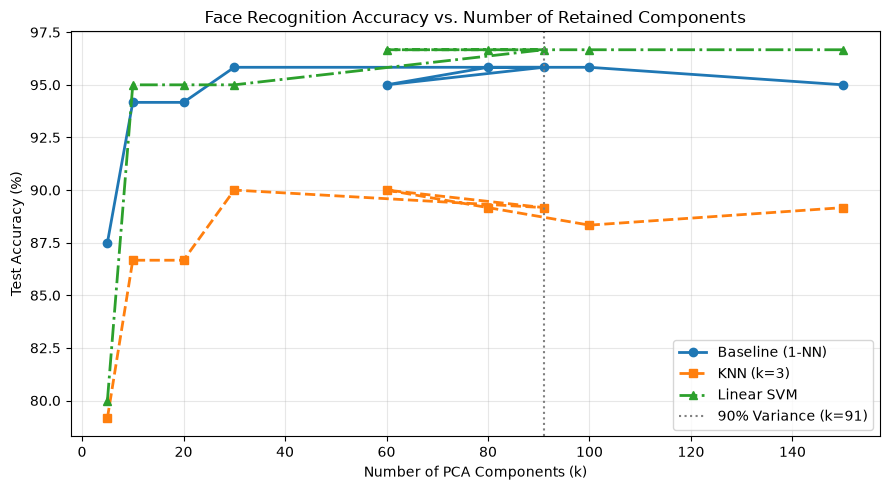

In [13]:
#PART-D

from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
import pandas as pd

# 1. Train traditional classifiers on W_train
classifiers = {
    "Baseline (Euclidean 1-NN)": None,  # already computed
    "K-Nearest Neighbors (k=3)": KNeighborsClassifier(n_neighbors=3, metric='euclidean'),
    "Support Vector Machine (Linear)": SVC(kernel='linear', C=1.0, random_state=42),
    "Support Vector Machine (RBF)": SVC(kernel='rbf', C=10.0, gamma='scale', random_state=42),
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42)
}

results = []
results.append({"Classifier": "Baseline (Euclidean 1-NN)", "Accuracy (%)": acc_pca})

for name, clf in classifiers.items():
    if clf is None:
        continue
    clf.fit(W_train, y_train)
    y_pred = clf.predict(W_test)
    acc = accuracy_score(y_test, y_pred) * 100
    results.append({"Classifier": name, "Accuracy (%)": acc})

results_df = pd.DataFrame(results)
print("=== Part D: Traditional ML Comparison ===")
print(results_df.to_string(index=False))

# 2. Experimenting with different numbers of retained components (k)
k_values = [5, 10, 20, 30, k_90, 60, 80, 100, 150]
knn_accs = []
svm_accs = []
baseline_accs = []

for k_cand in k_values:
    V_cand = eigenfaces_cov[:, :k_cand]
    W_tr = Phi_train @ V_cand
    W_te = Phi_test @ V_cand
    
    # Baseline 1-NN
    p_base, _, _ = nearest_neighbor_classify(W_tr, y_train, W_te)
    baseline_accs.append(np.mean(p_base == y_test) * 100)
    
    # KNN (k=3)
    knn_mod = KNeighborsClassifier(n_neighbors=3).fit(W_tr, y_train)
    knn_accs.append(accuracy_score(y_test, knn_mod.predict(W_te)) * 100)
    
    # Linear SVM
    svm_mod = SVC(kernel='linear', C=1.0, random_state=42).fit(W_tr, y_train)
    svm_accs.append(accuracy_score(y_test, svm_mod.predict(W_te)) * 100)

# Plot Accuracy vs Number of Components
plt.figure(figsize=(9, 5))
plt.plot(k_values, baseline_accs, 'o-', label="Baseline (1-NN)", lw=2)
plt.plot(k_values, knn_accs, 's--', label="KNN (k=3)", lw=2)
plt.plot(k_values, svm_accs, '^-.', label="Linear SVM", lw=2)
plt.axvline(x=k_90, color='gray', linestyle=':', label=f"90% Variance (k={k_90})")
plt.xlabel("Number of PCA Components (k)")
plt.ylabel("Test Accuracy (%)")
plt.title("Face Recognition Accuracy vs. Number of Retained Components")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig("accuracy_vs_components.png", dpi=150)
plt.show()